Using device: cuda

MNIST Dataset Loaded Successfully!
Training samples: 48000
Validation samples: 12000
Testing samples: 10000

Training Model 1 - Without Regularization
Without Regularization | Epoch [1/5] Train Loss: 0.3849 Val Loss: 0.2098 Train Acc: 94.51% Val Acc: 93.81%
Without Regularization | Epoch [2/5] Train Loss: 0.1602 Val Loss: 0.1552 Train Acc: 96.36% Val Acc: 95.33%
Without Regularization | Epoch [3/5] Train Loss: 0.1120 Val Loss: 0.1160 Train Acc: 97.55% Val Acc: 96.54%
Without Regularization | Epoch [4/5] Train Loss: 0.0823 Val Loss: 0.1111 Train Acc: 98.14% Val Acc: 96.71%
Without Regularization | Epoch [5/5] Train Loss: 0.0642 Val Loss: 0.1003 Train Acc: 98.68% Val Acc: 96.84%

Training Model 2 - L2 Regularization
L2 Regularization | Epoch [1/5] Train Loss: 0.4049 Val Loss: 0.2280 Train Acc: 93.82% Val Acc: 93.23%
L2 Regularization | Epoch [2/5] Train Loss: 0.1818 Val Loss: 0.1746 Train Acc: 95.57% Val Acc: 94.65%
L2 Regularization | Epoch [3/5] Train Loss: 0.1359 V

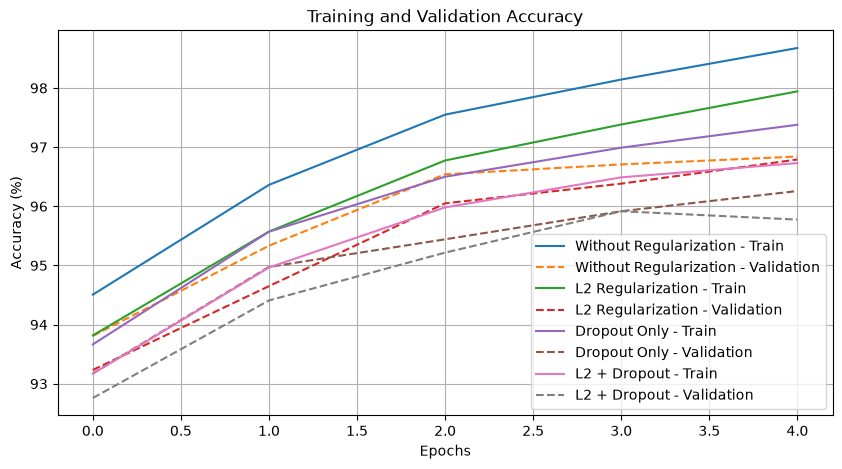

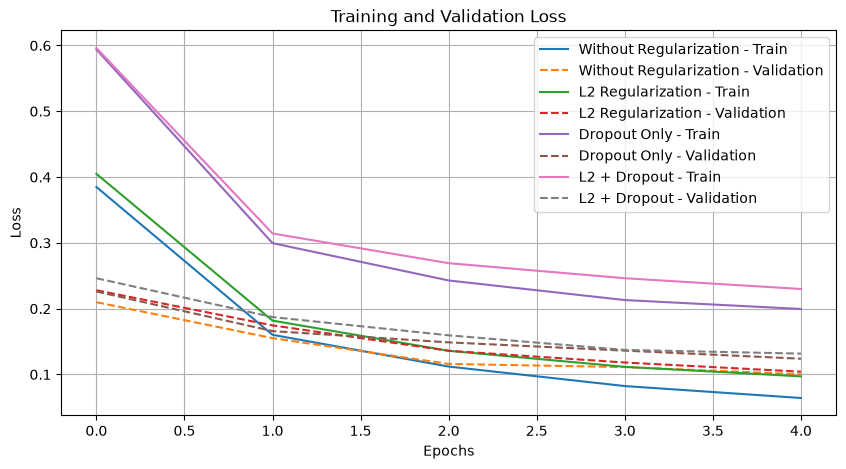

In [ ]:

# ============================================================
# PRACTICAL 3: EXPERIMENT WITH REGULARIZATION TECHNIQUES
# Dataset: MNIST
# Framework: PyTorch
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import struct
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, random_split, TensorDataset


# 1. DEVICE CONFIGURATION

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# 2. LOAD MNIST DATASET (OFFLINE FROM PEN DRIVE)

# Change F: to your actual pen drive letter
MNIST_PATH = Path(r"Cfile_path")


# Function to load images
def load_images(file_path):

    with open(file_path, 'rb') as f:

        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))

        images = np.frombuffer(f.read(), dtype=np.uint8).copy()

        images = images.reshape(num, 1, rows, cols)

        return torch.tensor(images, dtype=torch.float32) / 255.0


# Function to load labels
def load_labels(file_path):

    with open(file_path, 'rb') as f:

        magic, num = struct.unpack(">II", f.read(8))

        labels = np.frombuffer(f.read(), dtype=np.uint8).copy()

        return torch.tensor(labels, dtype=torch.long)


# Load training images and labels
train_images = load_images(
    MNIST_PATH / "train-images-idx3-ubyte"
)

train_labels = load_labels(
    MNIST_PATH / "train-labels-idx1-ubyte"
)


# Load testing images and labels
test_images = load_images(
    MNIST_PATH / "t10k-images-idx3-ubyte"
)

test_labels = load_labels(
    MNIST_PATH / "t10k-labels-idx1-ubyte"
)


# Create datasets
full_dataset = TensorDataset(train_images, train_labels)

test_dataset = TensorDataset(test_images, test_labels)


# Split training data into training and validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size]
)


# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False
)


print("\nMNIST Dataset Loaded Successfully!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


# 3. BUILD MLP MODEL

class MLP(nn.Module):

    def __init__(self, dropout=False):
        super(MLP, self).__init__()

        self.network = nn.Sequential(

            nn.Flatten(),

            nn.Linear(784, 128),
            nn.ReLU(),

            nn.Dropout(0.5) if dropout else nn.Identity(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Dropout(0.3) if dropout else nn.Identity(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


# 4. EVALUATION FUNCTION

def evaluate_model(model, loader, criterion):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(loader)

    accuracy = 100 * correct / total

    return avg_loss, accuracy


# 5. TRAINING FUNCTION

def train_model(model, name, l2=False, epochs=5):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    # Apply L2 regularization using weight_decay
    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.001 if l2 else 0
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        model.train()

        running_loss = 0

        # Training
        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)

        # Evaluate training and validation performance
        _, train_acc = evaluate_model(
            model, train_loader, criterion
        )

        val_loss, val_acc = evaluate_model(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"{name} | Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Val Loss: {val_loss:.4f} "
            f"Train Acc: {train_acc:.2f}% "
            f"Val Acc: {val_acc:.2f}%"
        )

    return model, history


# 6. MODEL 1 - WITHOUT REGULARIZATION

print("\nTraining Model 1 - Without Regularization")

model1 = MLP(dropout=False)

model1, history1 = train_model(
    model1,
    "Without Regularization",
    l2=False
)


# 7. MODEL 2 - WITH L2 REGULARIZATION

print("\nTraining Model 2 - L2 Regularization")

model2 = MLP(dropout=False)

model2, history2 = train_model(
    model2,
    "L2 Regularization",
    l2=True
)


# 8. MODEL 3 - WITH DROPOUT ONLY

print("\nTraining Model 3 - Dropout Only")

model3 = MLP(dropout=True)

model3, history3 = train_model(
    model3,
    "Dropout Only",
    l2=False
)


# 9. MODEL 4 - L2 + DROPOUT

print("\nTraining Model 4 - L2 + Dropout")

model4 = MLP(dropout=True)

model4, history4 = train_model(
    model4,
    "L2 + Dropout",
    l2=True
)


# 10. FINAL TEST ACCURACY COMPARISON

print("\n========== FINAL TEST RESULTS ==========")

models = [
    ("Without Regularization", model1),
    ("L2 Regularization", model2),
    ("Dropout Only", model3),
    ("L2 + Dropout", model4)
]

for name, model in models:

    test_loss, test_acc = evaluate_model(
        model, test_loader, nn.CrossEntropyLoss()
    )

    print(
        f"{name}: "
        f"Test Loss = {test_loss:.4f}, "
        f"Test Accuracy = {test_acc:.2f}%"
    )


# 11. PLOT TRAINING AND VALIDATION ACCURACY

histories = [
    ("Without Regularization", history1),
    ("L2 Regularization", history2),
    ("Dropout Only", history3),
    ("L2 + Dropout", history4)
]

plt.figure(figsize=(10, 5))

for name, history in histories:

    plt.plot(history["train_acc"], label=name + " - Train")

    plt.plot(history["val_acc"], linestyle="--",
             label=name + " - Validation")

plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()


# 12. PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

for name, history in histories:

    plt.plot(history["train_loss"], label=name + " - Train")

    plt.plot(history["val_loss"], linestyle="--",
             label=name + " - Validation")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.title("Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()


# ============================================================
# END OF PRACTICAL 3
# ============================================================
